# Used Car Price Prediction in Pakistan (PakWheels)

**Module 3 ML Project**

**GitHub repo:** https://github.com/saddamkhan11/pakwheels-car-price-prediction

Dataset: PakWheels used car listings (about 77,000 ads scraped from pakwheels.com).

## 1. Problem statement

**Predict** the asking price (PKR) of a used car **for** buyers and sellers on PakWheels **using** the car's make, model, year, engine size, mileage, transmission, fuel type, body type, assembly (local or imported), colour, city and registration city, **so that** a seller can set a fair price for an ad and a buyer can tell if a listed price is too high.

- **Label:** `price` (a number), so this is a **regression** problem.
- **Metrics:** MAE (average error in rupees, easy to explain) and R² (how much of the price variation the model explains).

## 2. Data
First I import the libraries for data handling, plotting and modelling.

In [1]:
# Data handling
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Modelling (scikit-learn)
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

import warnings
warnings.filterwarnings('ignore')

# Display settings so tables and charts are easy to read
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

I load the dataset. The original `pakwheels_used_cars.csv` had a broken `year` column (every row said 1905), so I use `pakwheels_used_car_data_v02.csv`. It has the same ads with real years, and year is one of the most important features for car price.

In [2]:
# Load the correct version of the data (v02 has real years)
df = pd.read_csv('pakwheels_used_car_data_v02.csv')
df.head()

,addref,city,assembly,body,make,model,year,engine,transmission,fuel,color,registered,mileage,price
0,7943732,Peshawar,NaN,Sedan,Toyota,Corolla,"2,013.00","1,300.00",Manual,Petrol,Silver Metallic,Lahore,145000,"2,870,000.00"
1,7730314,Lahore,NaN,Sedan,Honda,City,"2,000.00","1,300.00",Manual,Petrol,Blue,Lahore,230000,"995,000.00"
2,7943737,Lahore,NaN,Sedan,Toyota,Yaris,"2,021.00","1,300.00",Manual,Petrol,Super White,Punjab,60500,"3,585,000.00"
3,7943733,Lahore,NaN,Hatchback,Suzuki,Swift,"2,017.00","1,300.00",Manual,Petrol,Grey,Islamabad,87000,"2,250,000.00"
4,7923484,Lahore,NaN,Sedan,Honda,Civic,"2,017.00","1,800.00",Automatic,Petrol,Grey,Lahore,86000,"4,850,000.00"


I check the shape (rows, columns), the column names and the data types.

In [3]:
# Number of rows and columns
print('Shape:', df.shape)

# Column names and data types
df.info()

Shape: (77878, 14)
<class 'pandas.DataFrame'>
RangeIndex: 77878 entries, 0 to 77877
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   addref        77878 non-null  int64  
 1   city          77878 non-null  str    
 2   assembly      24189 non-null  str    
 3   body          68974 non-null  str    
 4   make          77878 non-null  str    
 5   model         77878 non-null  str    
 6   year          73099 non-null  float64
 7   engine        77875 non-null  float64
 8   transmission  77878 non-null  str    
 9   fuel          76972 non-null  str    
 10  color         76398 non-null  str    
 11  registered    77878 non-null  str    
 12  mileage       77878 non-null  int64  
 13  price         77295 non-null  float64
dtypes: float64(3), int64(2), str(9)
memory usage: 12.5 MB


I look at summary statistics to spot odd values, for example a 3cc engine or a 1,000,000 km mileage.

In [4]:
# Summary of numeric and text columns
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
addref,"77,878.00",NaN,NaN,NaN,"7,809,878.24","259,952.29","274,897.00","7,805,759.75","7,865,805.00","7,910,333.75","7,943,741.00"
city,77878,297,Lahore,16674,NaN,NaN,NaN,NaN,NaN,NaN,NaN
assembly,24189,1,Imported,24189,NaN,NaN,NaN,NaN,NaN,NaN,NaN
body,68974,21,Sedan,30193,NaN,NaN,NaN,NaN,NaN,NaN,NaN
make,77878,68,Toyota,24910,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,77878,435,Corolla,12871,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,"73,099.00",NaN,NaN,NaN,"2,012.81",7.52,"1,990.00","2,007.00","2,015.00","2,019.00","2,022.00"
engine,"77,875.00",NaN,NaN,NaN,"1,408.07",704.46,3.00,"1,000.00","1,300.00","1,600.00","15,000.00"
transmission,77878,2,Automatic,42763,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fuel,76972,3,Petrol,70620,NaN,NaN,NaN,NaN,NaN,NaN,NaN


I count missing values in each column and check for duplicate rows.

In [5]:
# Missing values: count and percentage per column
missing = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_%': (df.isna().mean() * 100).round(2)
}).sort_values('missing_count', ascending=False)
print(missing)

# Duplicate rows
print('\nDuplicate rows:', df.duplicated().sum())

              missing_count  missing_%
assembly              53689      68.94
body                   8904      11.43
year                   4779       6.14
color                  1480       1.90
fuel                    906       1.16
price                   583       0.75
engine                    3       0.00
make                      0       0.00
addref                    0       0.00
city                      0       0.00
model                     0       0.00
transmission              0       0.00
registered                0       0.00
mileage                   0       0.00

Duplicate rows: 0


**What I found:**
- `assembly` is 69% missing, but its only value is "Imported". On PakWheels a blank here means the car is **locally assembled**, so I fill it with "Local". This is a fixed rule per row, not something learned from the data, so it does not cause leakage.
- `price` is missing for 583 rows. We cannot train on rows with no label, so I drop them.
- `year`, `body`, `fuel`, `color` and `engine` have some missing values. I fill these **inside the Pipeline** (step 5), so the fill values come from the training data only.

### Basic cleaning (row rules only, nothing learned from the data)
I apply simple cleaning that only looks at one row at a time, so it is safe to do before the split:
- Fill `assembly` with "Local".
- Drop rows with no price.
- Drop impossible engine sizes (below 600cc or above 6600cc). These are typing mistakes in the ads.
- Drop prices above 200M PKR. The only one is a 2021 Corolla listed at 529M PKR, which is clearly a typo.
- Group over 380 colour spellings (e.g. "Super white", "Pearl White") into base colours.
- Drop `addref`, because it is just an ad ID and tells us nothing about price.

In [6]:
data = df.copy()

# 1) A blank assembly means a locally assembled car
data['assembly'] = data['assembly'].fillna('Local')

# 2) Rows without a label cannot be used for training
data = data.dropna(subset=['price'])

# 3) Remove impossible engine sizes (keep NaN, the pipeline will impute them)
bad_engine = (data['engine'] < 600) | (data['engine'] > 6600)
print('Rows with impossible engine size removed:', bad_engine.sum())
data = data[~bad_engine]

# 3b) Remove the obvious price typo (a 2021 Corolla listed at 529M PKR)
print('Rows with price above 200M removed:', (data['price'] > 2e8).sum())
data = data[data['price'] <= 2e8]

# 4) Simplify colour names into base colours
base_colours = ['white', 'black', 'grey', 'gray', 'silver', 'red', 'blue', 'green',
                'brown', 'yellow', 'orange', 'gold', 'beige', 'bronze', 'maroon']
def simplify_colour(c):
    if pd.isna(c):
        return np.nan                     # leave missing for the pipeline
    c = c.lower()
    for base in base_colours:
        if base in c:
            return 'Grey' if base == 'gray' else base.capitalize()
    return 'Other'
data['color'] = data['color'].apply(simplify_colour)

# 5) Drop the ad ID column
data = data.drop(columns=['addref'])

print('Shape after cleaning:', data.shape)
print('Colour groups:', data['color'].nunique())

Rows with impossible engine size removed: 207
Rows with price above 200M removed: 1


Shape after cleaning: (77087, 13)
Colour groups: 15


## 3. Exploratory Data Analysis (EDA)
I start with the label. Car prices are usually **right-skewed**: most cars are cheap and a few luxury cars cost a lot. I plot price on the normal scale and on a log scale.

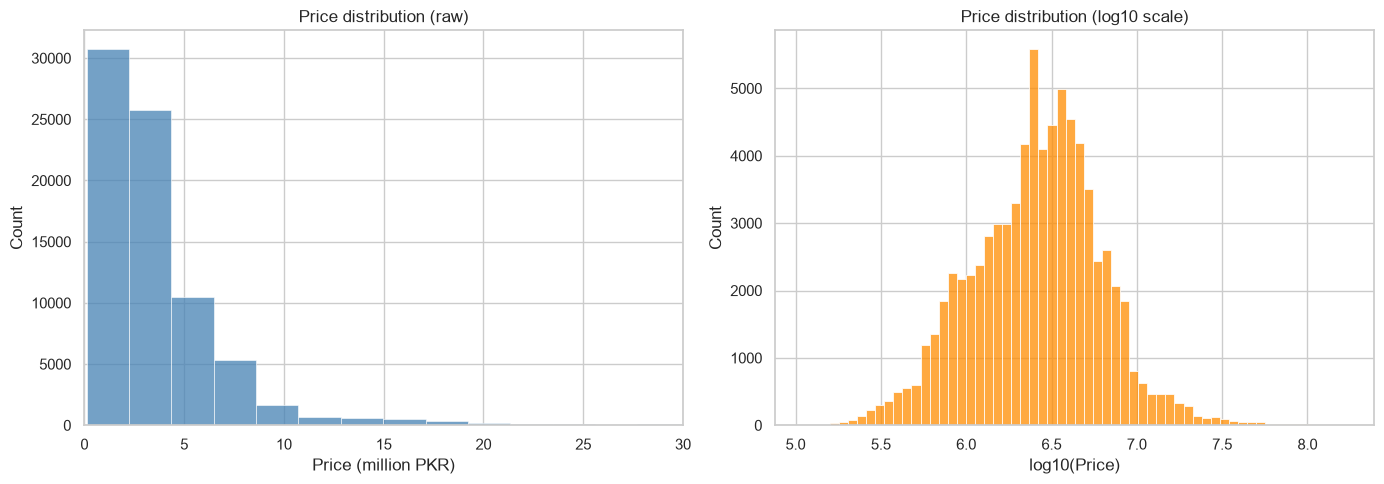

count         77,087
mean       3,825,028
std        5,160,807
min          110,000
25%        1,450,000
50%        2,700,000
75%        4,500,000
max      170,000,000
Name: price, dtype: str


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw price (in millions of PKR for readability)
sns.histplot(data['price'] / 1e6, bins=80, ax=axes[0], color='steelblue')
axes[0].set_title('Price distribution (raw)')
axes[0].set_xlabel('Price (million PKR)')
axes[0].set_xlim(0, 30)

# Log price
sns.histplot(np.log10(data['price']), bins=60, ax=axes[1], color='darkorange')
axes[1].set_title('Price distribution (log10 scale)')
axes[1].set_xlabel('log10(Price)')

plt.tight_layout()
plt.show()

print(data['price'].describe().apply(lambda x: f'{x:,.0f}'))

**Observation:** Price is very right-skewed (median 2.7M PKR, but the most expensive ads reach 170M PKR). On the log scale it looks close to a bell curve. So I will train the models on **log(price)**, which stops the few very expensive cars from dominating the errors, then convert predictions back to rupees.

I check how price changes with manufacturing year. I expect newer cars to cost more.

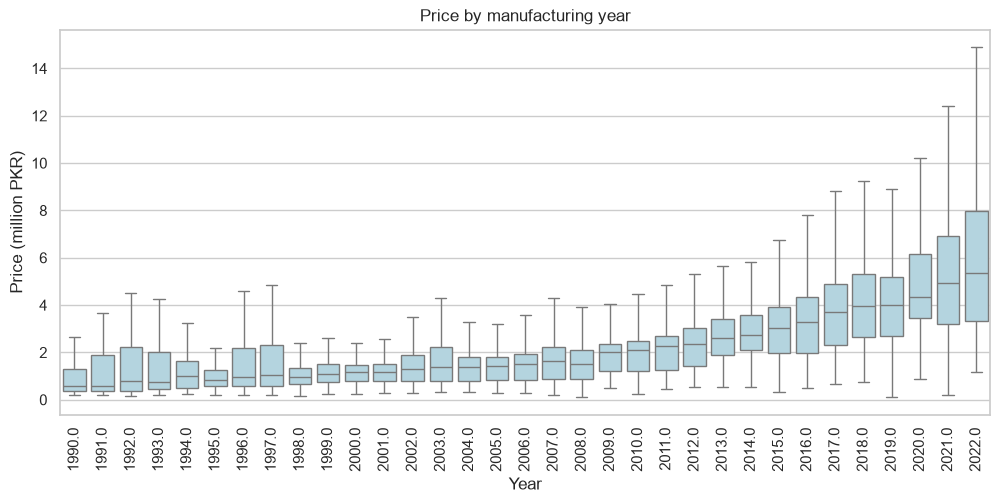

In [8]:
# Median price per year
yearly = data.groupby('year')['price'].median() / 1e6

plt.figure(figsize=(12, 5))
sns.boxplot(data=data, x='year', y=data['price'] / 1e6, showfliers=False, color='lightblue')
plt.title('Price by manufacturing year')
plt.xlabel('Year')
plt.ylabel('Price (million PKR)')
plt.xticks(rotation=90)
plt.show()

**Observation:** Price goes up clearly with year. Cars from 2018 onwards are much more expensive. Year will be a strong feature.

I compare prices across the 10 most common makes, because the brand matters a lot.

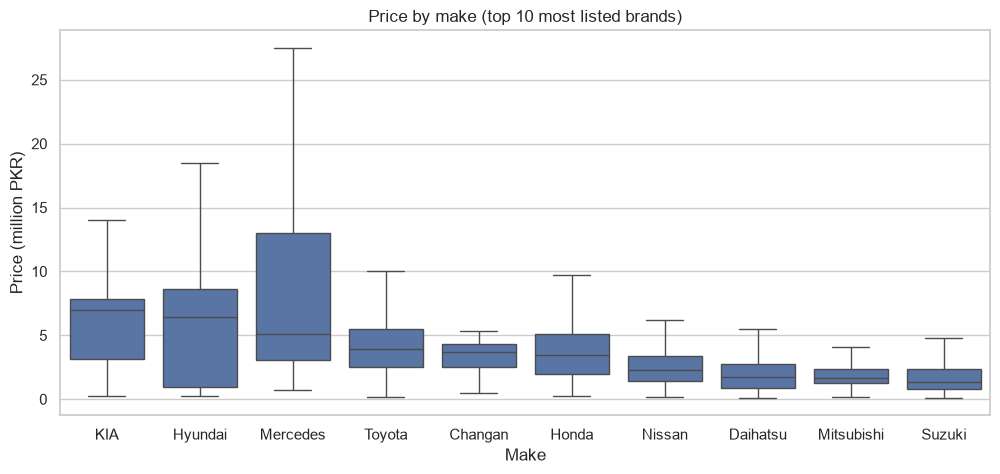

make
Toyota        24611
Suzuki        22279
Honda         16336
Daihatsu       3166
KIA            1750
Nissan         1513
Hyundai        1461
Mitsubishi     1094
Changan         937
Mercedes        575
Name: count, dtype: int64


In [9]:
top_makes = data['make'].value_counts().head(10).index
subset = data[data['make'].isin(top_makes)]
order = subset.groupby('make')['price'].median().sort_values(ascending=False).index

plt.figure(figsize=(12, 5))
sns.boxplot(data=subset, x='make', y=subset['price'] / 1e6, order=order, showfliers=False)
plt.title('Price by make (top 10 most listed brands)')
plt.xlabel('Make')
plt.ylabel('Price (million PKR)')
plt.show()

# How many ads per make
print(data['make'].value_counts().head(10))

**Observation:** Toyota, Suzuki and Honda make up most ads. Suzuki and Daihatsu are cheap small cars, while KIA, Hyundai and Toyota cost more. Make and model will be important.

I check how mileage relates to price. More km driven should mean a lower price.

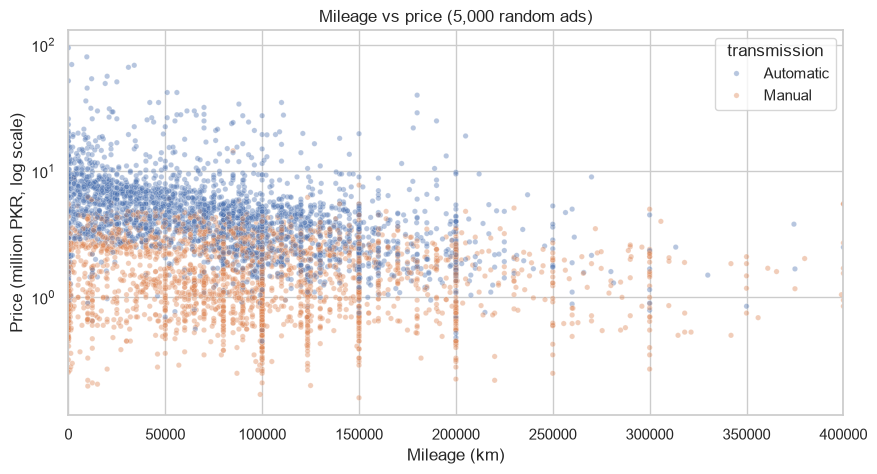

In [10]:
sample = data.sample(5000, random_state=42)   # sample so the plot is not overcrowded

plt.figure(figsize=(10, 5))
sns.scatterplot(data=sample, x='mileage', y=sample['price'] / 1e6, hue='transmission', alpha=0.4, s=15)
plt.yscale('log')
plt.xlim(0, 400000)
plt.title('Mileage vs price (5,000 random ads)')
plt.xlabel('Mileage (km)')
plt.ylabel('Price (million PKR, log scale)')
plt.show()

**Observation:** Higher mileage tends to mean a lower price, but the spread is wide. Automatic cars (orange) are generally priced higher than manual ones.

I compare price by transmission, assembly and fuel type.

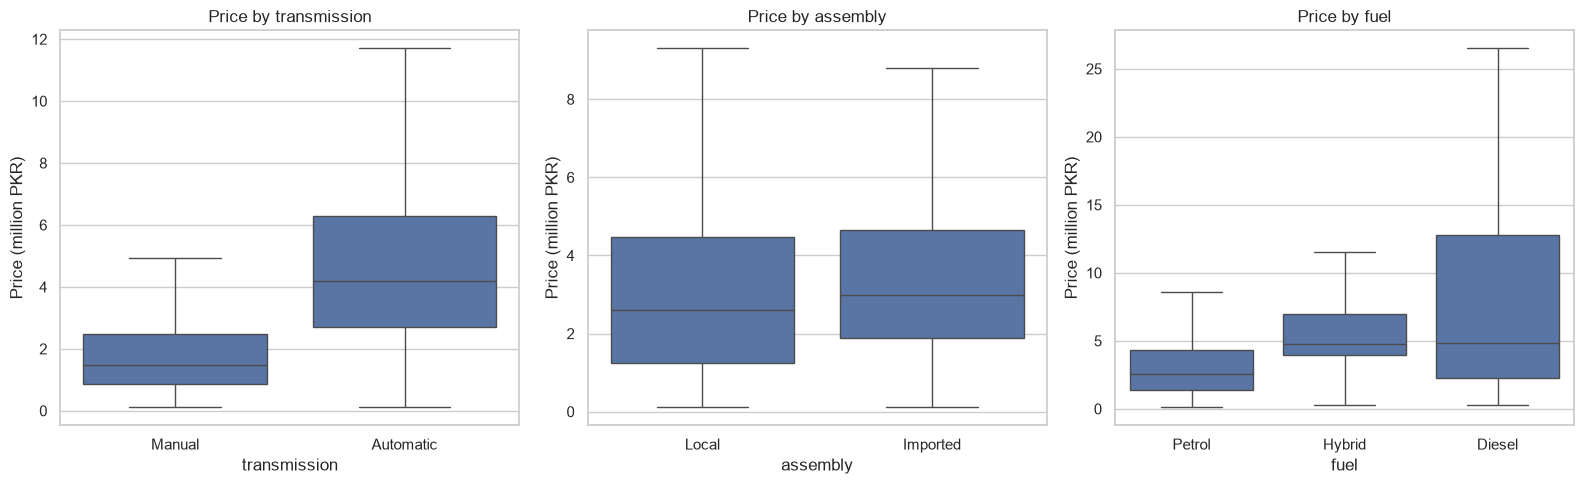

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, ['transmission', 'assembly', 'fuel']):
    sns.boxplot(data=data, x=col, y=data['price'] / 1e6, showfliers=False, ax=ax)
    ax.set_title(f'Price by {col}')
    ax.set_ylabel('Price (million PKR)')
plt.tight_layout()
plt.show()

**Observation:** Automatic, imported and hybrid/diesel cars sell for more. Each of these columns gives the model useful information.

I check how the numeric features correlate with price (using log price, since that is what the model will learn).

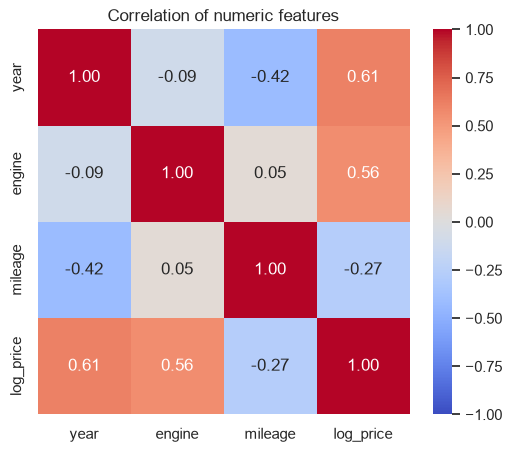

In [12]:
num = data[['year', 'engine', 'mileage']].copy()
num['log_price'] = np.log10(data['price'])

plt.figure(figsize=(6, 5))
sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation of numeric features')
plt.show()

**Observation:** Year (+) and engine size (+) have the strongest links to price, and mileage is negative. Year and mileage are also linked to each other, because older cars have driven more.

## 4. Train/test split and baseline
I split the data **before** any learned preprocessing: 80% train, 20% test, `random_state=42`. The test set stays untouched until the final evaluation.

In [13]:
# Features (X) and label (y)
X = data.drop(columns=['price'])
y = data['price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (61669, 12)  Test: (15418, 12)


**Baseline:** a model that always predicts the **median training price** for every car. Any real model must beat this to be useful. I use the median because it is less affected by the very expensive cars than the mean.

In [14]:
baseline = DummyRegressor(strategy='median')
baseline.fit(X_train, y_train)
base_pred = baseline.predict(X_test)

baseline_mae = mean_absolute_error(y_test, base_pred)
baseline_r2 = r2_score(y_test, base_pred)
print(f'Baseline prediction for every car: {base_pred[0]:,.0f} PKR')
print(f'Baseline MAE: {baseline_mae:,.0f} PKR')
print(f'Baseline R2 : {baseline_r2:.3f}')

Baseline prediction for every car: 2,700,000 PKR
Baseline MAE: 2,354,477 PKR
Baseline R2 : -0.043


The baseline is off by about 2.3M PKR per car on average and its R² is just below 0, so it explains nothing. This is the score to beat.

## 5. Preprocessing Pipeline (no leakage)
I build all preprocessing into a `ColumnTransformer` inside a `Pipeline`, so imputers, encoders and scalers are **fitted on the training folds only**, and cross-validation stays honest.
- **Numeric** (`year`, `engine`, `mileage`): fill missing values with the median, then scale.
- **Categorical** (`make`, `model`, `city`, ...): fill missing values with "Unknown", then one-hot encode. Rare categories (fewer than 20 ads) are grouped into one "infrequent" column, and unseen categories in the test set are handled without errors.
- **Target:** `TransformedTargetRegressor` trains on `log(price)` and converts predictions back to PKR, so MAE is still in rupees.

In [15]:
numeric_features = ['year', 'engine', 'mileage']
categorical_features = ['city', 'assembly', 'body', 'make', 'model',
                        'transmission', 'fuel', 'color', 'registered']

# Steps for numeric columns
numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Steps for categorical columns
categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('onehot', OneHotEncoder(handle_unknown='infrequent_if_exist',
                             min_frequency=20, sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipe, numeric_features),
    ('cat', categorical_pipe, categorical_features)
])

def make_model(regressor):
    """Preprocessing + regressor in one pipeline, trained on log(price)."""
    pipe = Pipeline([('prep', preprocessor), ('model', regressor)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

# Check how many columns the preprocessing creates (fitted on train only)
n_cols = preprocessor.fit(X_train).transform(X_train.head()).shape[1]
print('Number of features after encoding:', n_cols)

Number of features after encoding: 371


## 6. Model comparison with cross-validation
I compare 3 models with **5-fold cross-validation on the training set only**:
1. **Ridge Regression**: a simple linear model, fast and easy to explain.
2. **Random Forest**: many decision trees averaged. It handles non-linear effects (e.g. year × make).
3. **HistGradientBoosting**: trees built one after another, each fixing the previous errors. Usually strong on tabular data.

The baseline is included in the same CV so every model is compared the same way.

In [16]:
models = {
    'Baseline (median)': make_model(DummyRegressor(strategy='median')),
    'Ridge Regression': make_model(Ridge(alpha=1.0)),
    'Random Forest': make_model(RandomForestRegressor(
        n_estimators=100, min_samples_leaf=2, n_jobs=-1, random_state=42)),
    'HistGradientBoosting': make_model(HistGradientBoostingRegressor(
        max_iter=500, learning_rate=0.1, random_state=42)),
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv,
                            scoring=['neg_mean_absolute_error', 'r2'], n_jobs=1)
    results.append({
        'Model': name,
        'CV MAE (PKR)': -scores['test_neg_mean_absolute_error'].mean(),
        'CV MAE std': scores['test_neg_mean_absolute_error'].std(),
        'CV R2': scores['test_r2'].mean(),
        'CV R2 std': scores['test_r2'].std(),
    })
    print(f'{name:22s} done')

results_df = pd.DataFrame(results).sort_values('CV MAE (PKR)')
results_df

Baseline (median)      done


Ridge Regression       done


Random Forest          done


HistGradientBoosting   done


,Model,CV MAE (PKR),CV MAE std,CV R2,CV R2 std
2,Random Forest,"360,379.29","5,466.49",0.90,0.02
3,HistGradientBoosting,"384,307.23","1,343.25",0.91,0.02
1,Ridge Regression,"747,866.84","13,180.27",0.72,0.03
0,Baseline (median),"2,332,394.48","44,120.73",-0.05,0.00


I plot the CV results so the comparison is easy to see (lower MAE is better, higher R² is better).

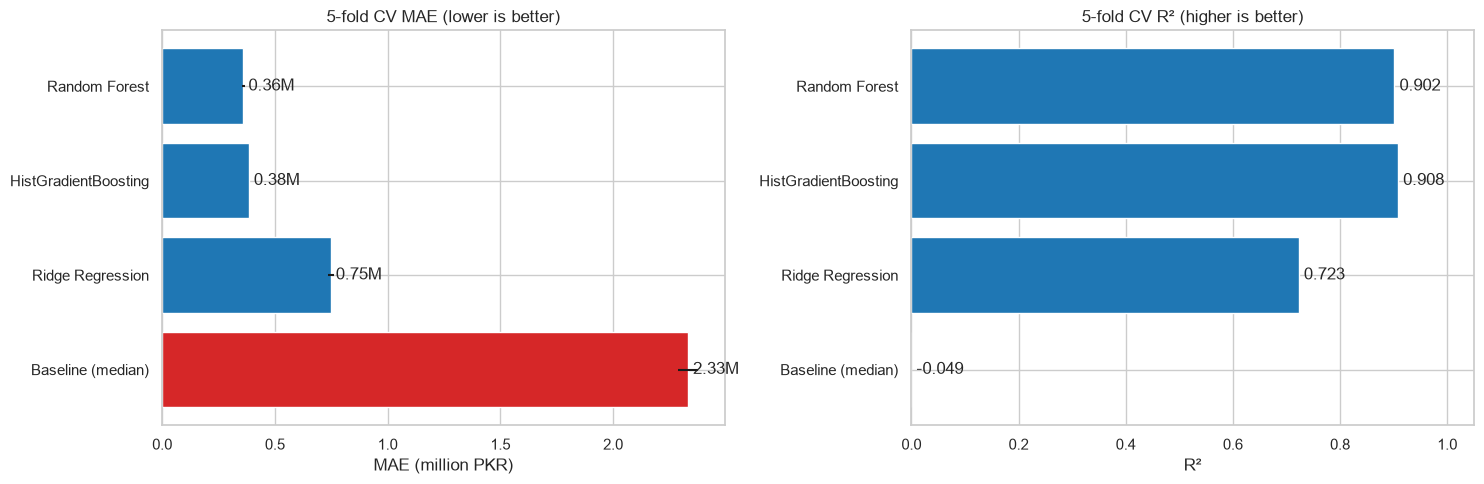

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot_df = results_df.sort_values('CV MAE (PKR)', ascending=False)
colors = ['#d62728' if 'Baseline' in m else '#1f77b4' for m in plot_df['Model']]

axes[0].barh(plot_df['Model'], plot_df['CV MAE (PKR)'] / 1e6, xerr=plot_df['CV MAE std'] / 1e6, color=colors)
axes[0].set_title('5-fold CV MAE (lower is better)')
axes[0].set_xlabel('MAE (million PKR)')
for i, v in enumerate(plot_df['CV MAE (PKR)'] / 1e6):
    axes[0].text(v, i, f' {v:.2f}M', va='center')

axes[1].barh(plot_df['Model'], plot_df['CV R2'].clip(lower=0), color=colors)
axes[1].set_title('5-fold CV R² (higher is better)')
axes[1].set_xlabel('R²')
axes[1].set_xlim(0, 1.05)
for i, v in enumerate(plot_df['CV R2']):
    axes[1].text(max(v, 0), i, f' {v:.3f}', va='center')

plt.tight_layout()
plt.show()

**Which model I chose and why:** I pick the model with the **lowest CV MAE** (printed below). Random Forest has the lowest MAE, while HistGradientBoosting has a very similar R² and is faster. I choose Random Forest because MAE (rupees off per car) matters most to a buyer or seller. Both tree models beat the baseline and Ridge by a wide margin, because car price depends on **combinations** of features (a 2020 Corolla is worth much more than a 2005 Corolla, but a 2020 Mehran is still cheap). A straight-line model cannot capture this. The small standard deviation across folds shows the score is stable.

In [18]:
best_name = results_df.iloc[0]['Model']
print('Chosen model:', best_name)
print(f"CV MAE improvement over baseline: "
      f"{(1 - results_df.iloc[0]['CV MAE (PKR)'] / results_df[results_df.Model.str.contains('Baseline')]['CV MAE (PKR)'].iloc[0]) * 100:.1f}%")

Chosen model: Random Forest
CV MAE improvement over baseline: 84.5%


## 7. Evaluation on the test set
I train the chosen model on the full training set and score it **once** on the held-out test set.

In [19]:
final_model = models[best_name]
final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)

test_mae = mean_absolute_error(y_test, y_pred)
test_r2 = r2_score(y_test, y_pred)
test_mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100

print(f'Test MAE : {test_mae:,.0f} PKR')
print(f'Test R2  : {test_r2:.3f}')
print(f'Test MAPE: {test_mape:.1f}%  (average error as % of the real price)')
print()
print(f'Baseline MAE was {baseline_mae:,.0f} PKR -> the model cuts the error by {(1 - test_mae / baseline_mae) * 100:.1f}%')

Test MAE : 367,008 PKR
Test R2  : 0.832
Test MAPE: 11.4%  (average error as % of the real price)

Baseline MAE was 2,354,477 PKR -> the model cuts the error by 84.4%


The test MAE (≈367k PKR) is almost the same as the CV MAE (≈360k PKR), so the model is **not overfitting** and should work the same way on new ads. Test R² (0.83) is a bit lower than CV R² (0.90). R² is very sensitive to a few very expensive cars (Land Cruiser, Lexus LX), because squared errors on 100M+ cars dominate it. This is why MAE is the main metric here.

I plot actual vs predicted prices. Points on the red line are perfect predictions.

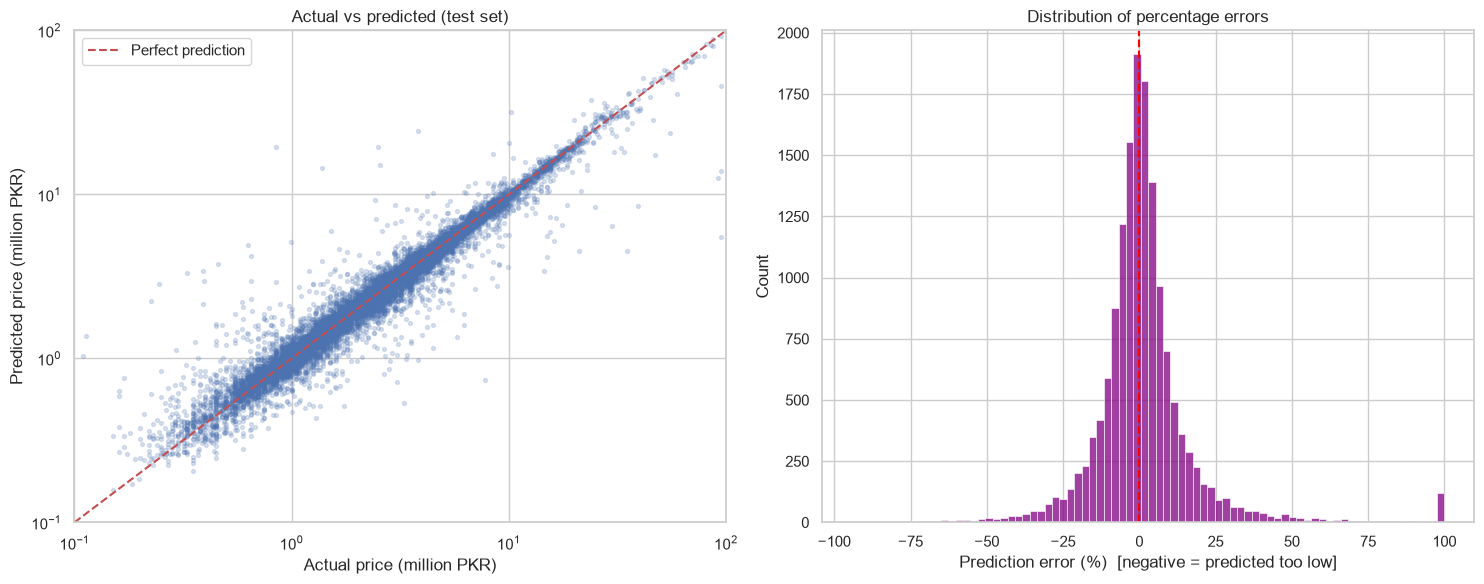

Ads predicted within 10% of the real price: 68.6%
Ads predicted within 20% of the real price: 87.4%


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Actual vs predicted (log scales so cheap and expensive cars are both visible)
axes[0].scatter(y_test / 1e6, y_pred / 1e6, alpha=0.2, s=8)
lims = [0.1, 100]
axes[0].plot(lims, lims, 'r--', label='Perfect prediction')
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_xlim(lims); axes[0].set_ylim(lims)
axes[0].set_xlabel('Actual price (million PKR)')
axes[0].set_ylabel('Predicted price (million PKR)')
axes[0].set_title('Actual vs predicted (test set)')
axes[0].legend()

# Distribution of percentage errors
pct_error = (y_pred - y_test) / y_test * 100
sns.histplot(pct_error.clip(-100, 100), bins=80, ax=axes[1], color='purple')
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_xlabel('Prediction error (%)  [negative = predicted too low]')
axes[1].set_title('Distribution of percentage errors')

plt.tight_layout()
plt.show()

print(f'Ads predicted within 10% of the real price: {(pct_error.abs() <= 10).mean() * 100:.1f}%')
print(f'Ads predicted within 20% of the real price: {(pct_error.abs() <= 20).mean() * 100:.1f}%')

### What does the model get wrong, and why?
First I check the error by **price band**. Then I look at the **largest individual errors**.

             ads      MAE_PKR  median_pct_error
price_band                                     
<1M         2447   140,954.76             11.68
1-2M        3234   176,988.78              7.61
2-4M        5095   253,889.59              5.29
4-8M        3472   346,764.80              3.91
8-15M        824   830,337.54              4.56
>15M         346 4,507,218.50              5.20


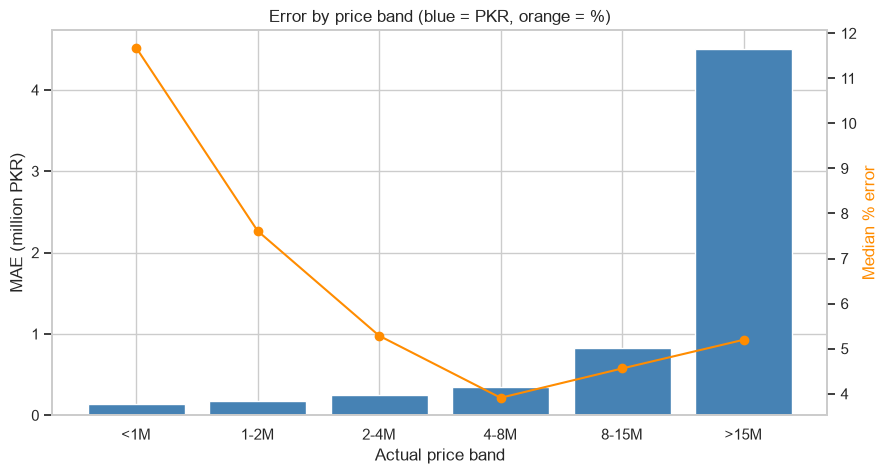

In [21]:
results_test = X_test.copy()
results_test['actual'] = y_test
results_test['predicted'] = y_pred
results_test['abs_error'] = (results_test['predicted'] - results_test['actual']).abs()
results_test['pct_error'] = results_test['abs_error'] / results_test['actual'] * 100

# Error per price band
bands = [0, 1e6, 2e6, 4e6, 8e6, 15e6, np.inf]
labels = ['<1M', '1-2M', '2-4M', '4-8M', '8-15M', '>15M']
results_test['price_band'] = pd.cut(results_test['actual'], bins=bands, labels=labels)

band_summary = results_test.groupby('price_band', observed=True).agg(
    ads=('actual', 'size'),
    MAE_PKR=('abs_error', 'mean'),
    median_pct_error=('pct_error', 'median')
)
print(band_summary)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(band_summary.index.astype(str), band_summary['MAE_PKR'] / 1e6, color='steelblue')
ax1.set_ylabel('MAE (million PKR)')
ax1.set_xlabel('Actual price band')
ax2 = ax1.twinx()
ax2.plot(band_summary.index.astype(str), band_summary['median_pct_error'], 'o-', color='darkorange')
ax2.set_ylabel('Median % error', color='darkorange')
ax2.grid(False)
plt.title('Error by price band (blue = PKR, orange = %)')
plt.show()

**Observation:** In rupees, the error grows a lot for expensive cars (above 8M PKR), because a 5% miss on a 30M car is still 1.5M rupees, and there are **far fewer** luxury cars to learn from. In percentage terms, the **cheapest cars (under 1M PKR) have the highest error**. These are mostly old cars, whose price depends on condition, which the data does not record.

I list the 10 test ads with the biggest percentage errors to see what they have in common.

In [22]:
cols = ['make', 'model', 'year', 'engine', 'mileage', 'assembly', 'city', 'actual', 'predicted', 'pct_error']
worst = results_test.sort_values('pct_error', ascending=False)[cols].head(10)
worst.style.format({'actual': '{:,.0f}', 'predicted': '{:,.0f}', 'pct_error': '{:.0f}%',
                    'mileage': '{:,.0f}', 'year': '{:.0f}', 'engine': '{:.0f}'})

,make,model,year,engine,mileage,assembly,city,actual,predicted,pct_error
60879,Mercedes,Benz,nan,1800,"12,345",Imported,Lahore,"850,000","19,392,853",2182%
197,FAW,X-PV,2019,1000,"41,000",Local,Hafizabad,"113,000","1,374,543",1116%
35842,Toyota,Corolla,2010,1800,"160,000",Local,Rawalpindi,"245,000","2,848,959",1063%
28612,Toyota,Cressida,nan,3000,"2,500",Imported,Lahore,"1,380,000","14,480,573",949%
1649,Toyota,Corolla,2015,1300,"85,000",Local,Karachi,"330,000","3,316,276",905%
16051,Toyota,Corolla,nan,1300,"7,869",Local,Karachi,"225,000","2,242,843",897%
210,Daihatsu,Cuore,2008,800,"140,000",Imported,Peshawar,"110,000","1,039,890",845%
37519,Toyota,Corolla,nan,1300,"10,000",Imported,Lahore,"390,000","3,429,647",779%
60715,Suzuki,Swift,nan,1000,"20,000",Imported,Islamabad,"460,000","3,748,336",715%
75621,Toyota,Corolla,nan,1800,"1,800",Local,Nowshera,"630,000","4,911,072",680%


I check which makes and models have the highest average % error, counting only those with at least 30 test ads so the numbers are reliable.

In [23]:
make_err = (results_test.groupby('make')
            .agg(ads=('pct_error', 'size'), median_pct_error=('pct_error', 'median'))
            .query('ads >= 30')
            .sort_values('median_pct_error', ascending=False))
print(make_err.head(10))

            ads  median_pct_error
make                             
FAW          55             16.43
Mercedes    121             16.11
BMW          39             15.73
Mazda        50             14.67
Chevrolet    30             12.72
Mitsubishi  234             12.33
Nissan      307              8.03
Daihatsu    630              7.84
Audi         39              7.77
Prince       42              6.80


I use **permutation importance** to see which original columns the model relies on most. It measures how much the test MAE gets worse when one column is shuffled.

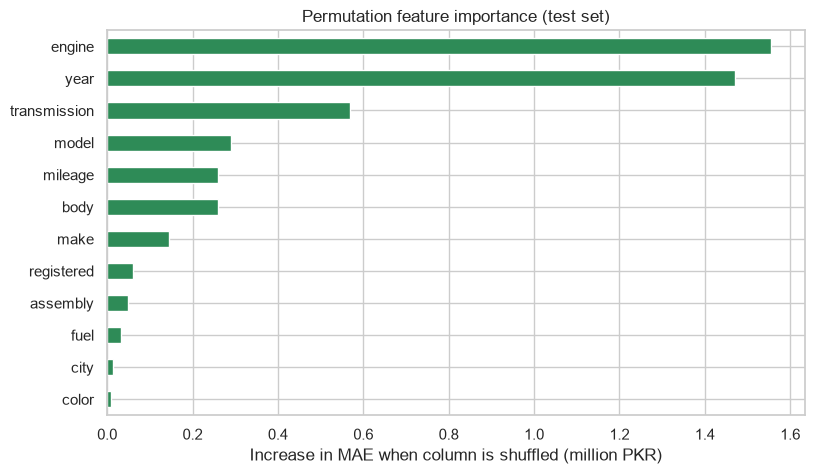

In [24]:
# Use a sample of the test set to keep this fast
X_imp = X_test.sample(4000, random_state=42)
y_imp = y_test.loc[X_imp.index]

imp = permutation_importance(final_model, X_imp, y_imp, n_repeats=5,
                             scoring='neg_mean_absolute_error', random_state=42, n_jobs=1)
importance = pd.Series(imp.importances_mean, index=X_imp.columns).sort_values()

plt.figure(figsize=(9, 5))
(importance / 1e6).plot(kind='barh', color='seagreen')
plt.xlabel('Increase in MAE when column is shuffled (million PKR)')
plt.title('Permutation feature importance (test set)')
plt.show()

### Why the model makes these mistakes
1. **Wrong or fake prices in the ads.** Many of the worst errors are ads whose listed price makes no sense for that car (for example a recent car listed for a few lakh, or a price typed with an extra or missing zero). The model predicts a sensible price, but the "true" label is the mistake. No model can learn these.
2. **Rare and luxury cars.** There are few ads for imported luxury models (Land Cruiser, Mercedes, BMW, Prado), so the model has less to learn from. Prices for these cars also vary a lot by trim and condition.
3. **Missing information.** The dataset has no **trim/variant** (e.g. Corolla GLi vs Altis Grande), **condition**, **accident history** or **import year** for imported cars. Two cars with the same features can have very different real prices, and the model cannot tell them apart.
4. **Mileage is self-reported.** Some ads show very low or round mileage (1 km, 123456 km), which confuses the model for those cars.

**How to improve:** remove clearly wrong prices with stricter cleaning rules, add trim/variant and condition features if available, and tune the hyperparameters of the chosen model (e.g. with `GridSearchCV` on the training set).

## 8. Conclusion
- **Problem:** predict used car prices in Pakistan to help sellers price ads and buyers spot overpriced ads.
- **Data:** ~77k PakWheels ads, 13 features, cleaned with row-level rules. All learned preprocessing is inside a Pipeline.
- **EDA:** price is very skewed (so I modelled log price). Year, make/model, engine size and transmission matter most.
- **Models:** the baseline, Ridge, Random Forest and HistGradientBoosting were compared with 5-fold CV. The tree models were far better than the baseline and the linear model.
- **Result:** the chosen model's MAE and R² on the test set are printed in section 7, and the scores are much better than the baseline.
- **Limitations:** wrong prices in ads, few luxury cars, and no trim/condition data.